# CS 521 HW4, Problem 1: Interval Bound Propagation (IBP) Training

Fully connected network (3 hidden layers x 50 ReLU), MNIST, $\ell_\infty$ threat model with $\epsilon_\infty = 0.1$.

In [ ]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

EPS = {"linf": 0.1, "l2": 1.0}     # the radii of the threat model

device: cuda


# Data and model

The network has 3 hidden layers with 50 neurons. It has no normalization layer.

In [ ]:
def load_mnist(train):
    ds = torchvision.datasets.MNIST("data", train=train, download=True)
    x = ds.data.float().div(255).unsqueeze(1)  # (n, 1, 28, 28)
    return x.to(device), ds.targets.to(device)


def batches(x, y, batch_size, shuffle):
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        j = idx[i:i + batch_size]
        yield x[j], y[j]


x_train, y_train = load_mnist(train=True)
x_test, y_test = load_mnist(train=False)
print(x_train.shape, x_test.shape)


def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


def linear_layers(model):
    return [m for m in model if isinstance(m, nn.Linear)]

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


# Attacks

`pgd(model, x, y, eps, norm, steps)` is an untargeted PGD attack with a random start.
Use `norm="linf"` or `norm="l2"`. The function returns the adversarial images of the restart with the highest loss.

In [ ]:
def _project(delta, eps, norm):
    if norm == "linf":
        return delta.clamp(-eps, eps)
    n = delta.flatten(1).norm(dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
    return delta * (eps / n).clamp(max=1.0)


def pgd(model, x, y, eps, norm, steps=10, alpha=None, restarts=1):
    alpha = alpha or 2.5 * eps / steps
    best_x, best_loss = x.clone(), torch.full((len(x),), -float("inf"), device=x.device)
    for _ in range(restarts):
        if norm == "linf":
            delta = (torch.rand_like(x) * 2 - 1) * eps
        else:
            delta = torch.randn_like(x)
            r = torch.rand(len(x), 1, 1, 1, device=x.device) * eps
            delta = delta / delta.flatten(1).norm(dim=1).view(-1, 1, 1, 1) * r
        delta = (x + delta).clamp(0, 1) - x
        for _ in range(steps):
            delta.requires_grad_(True)
            loss = F.cross_entropy(model(x + delta), y)
            grad, = torch.autograd.grad(loss, delta)
            with torch.no_grad():
                if norm == "linf":
                    step = grad.sign()
                else:
                    step = grad / grad.flatten(1).norm(dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
                delta = _project(delta + alpha * step, eps, norm)
                delta = (x + delta).clamp(0, 1) - x
        with torch.no_grad():
            loss = F.cross_entropy(model(x + delta), y, reduction="none")
            better = loss > best_loss
            best_x[better], best_loss[better] = (x + delta)[better], loss[better]
    return best_x.detach()

# Verifier (box / IBP)

`ibp_margin_bounds(model, c, r, norm, y)` propagates the box $[c - r, c + r] \cap [0, 1]^{784}$ through the network.
The last linear layer is merged with the specification, so `m[:, j]` is a lower bound of $f_y - f_j$ and `m[:, y] = 0`.
`box_verified` certifies an image if all margin lower bounds are positive. This is the only verifier used.

In [ ]:
def first_layer_bounds(layer, c, r, norm):
    c = c.flatten(1)
    if norm == "linf":
        l, u = (c - r).clamp(0, 1), (c + r).clamp(0, 1)
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
    else:
        mid, rad = layer(c), r * layer.weight.norm(dim=1)
    return mid - rad, mid + rad


def ibp_margin_bounds(model, c, r, norm, y):
    layers = linear_layers(model)
    l, u = first_layer_bounds(layers[0], c, r, norm)
    for layer in layers[1:-1]:
        l, u = F.relu(l), F.relu(u)
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
        l, u = mid - rad, mid + rad
    l, u = F.relu(l), F.relu(u)
    last = layers[-1]
    w = last.weight[y].unsqueeze(1) - last.weight.unsqueeze(0)  # (batch, 10, n): W_y - W_j
    b = last.bias[y].unsqueeze(1) - last.bias.unsqueeze(0)
    mid, rad = (u + l) / 2, (u - l) / 2
    return (w @ mid.unsqueeze(2)).squeeze(2) - (w.abs() @ rad.unsqueeze(2)).squeeze(2) + b, (w @ mid.unsqueeze(2)).squeeze(2) + (w.abs() @ rad.unsqueeze(2)).squeeze(2) + b


@torch.no_grad()
def box_verified(model, x, y, eps, norm="linf"):
    lower, _ = ibp_margin_bounds(model, x, eps, norm, y)
    m = lower.clone()
    m[torch.arange(len(y)), y] = float("inf")
    return m.min(dim=1).values > 0

# Evaluation

`evaluate(model, name)` uses the 10,000 test images. It returns the standard accuracy (`clean`), the box-verified accuracy
at $\epsilon = 0.1$ (`verified`) and the PGD accuracy (50 steps, `pgd_linf`), which is an upper bound of the true robust accuracy.

In [ ]:
def evaluate(model, name, eps=EPS["linf"], n=10000, batch_size=1000):
    model.eval()
    counts = {"clean": 0, "verified": 0, "pgd_linf": 0}
    for x, y in batches(x_test[:n], y_test[:n], batch_size, False):
        with torch.no_grad():
            correct = model(x).argmax(1) == y
        counts["clean"] += correct.sum().item()
        counts["verified"] += (box_verified(model, x, y, eps) & correct).sum().item()
        x_adv = pgd(model, x, y, eps, "linf", steps=50)
        with torch.no_grad():
            counts["pgd_linf"] += (correct & (model(x_adv).argmax(1) == y)).sum().item()
    res = {"name": name}
    res.update({k: 100 * v / n for k, v in counts.items()})
    return res


def print_results(rows):
    for r in rows:
        print(f"{r['name']:<10}" + "  ".join(f"{k} {v:6.2f}" for k, v in r.items()
                                     if k != "time" and isinstance(v, float)) +
              (f"  time/epoch {r['time']:5.1f} s" if "time" in r else ""))

# Training loop

For each batch, `train(model, loss_fn)` calls `loss_fn(model, x, y, t)` and does one optimizer step.
The value `t` is the training progress in epochs (a float). The schedule is:

* For $t < 1$, `scale_scheduler(t)` is 0 (standard training).
* For $1 \leq t < 11$, `scale_scheduler(t)` increases linearly from 0 to 1.
* For $t \geq 11$, `scale_scheduler(t)` is 1.

In [ ]:
WARMUP, RAMP = 1, 10
LR = 4e-3


def scale_scheduler(t):
    return 0.0 if t <= WARMUP else min((t - WARMUP) / RAMP, 1.0)


def train(model, loss_fn, epochs=20, lr=LR, batch_size=512, seed=0, gp_beta=None, verbose=True):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    params = [p for p in model.parameters() if p.requires_grad]
    n_batches = (len(x_train) + batch_size - 1) // batch_size
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for i, (x, y) in enumerate(batches(x_train, y_train, batch_size, True)):
            t = epoch + i / n_batches
            loss = loss_fn(model, x, y, t)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        sched.step()
        if verbose:
            print(f"epoch {epoch + 1:2d}  loss {total / n_batches:.4f}  time {time.time() - start:.0f} s")
    return (time.time() - start) / epochs

# (a) IBP training

$L_{IBP} = \kappa \cdot CE(z_K, y) + (1-\kappa) \cdot CE(\hat z_K(\epsilon_{train}), y)$, with the last layer merged into the specification (Eq. 9),
so $\hat z = -\underline{m}$ where $\underline{m}_j$ is the IBP lower bound of $f_y - f_j$ ($\underline{m}_y = 0$, hence $\hat z_y = 0$).

Both $\kappa$ and $\epsilon_{train}$ follow `scale_scheduler(t)`:
* $\epsilon_{train} = 0.1 \cdot$ `scale_scheduler(t)` (0 → 0.1)
* $\kappa = 1 - 0.5 \cdot$ `scale_scheduler(t)` (1 → 0.5)

In [ ]:
def standard_loss(model, x, y, t):
    return F.cross_entropy(model(x), y)


def ibp_loss(model, x, y, t, norm="linf"):
    s = scale_scheduler(t)
    k = 1.0 - 0.5 * s                      # kappa: 1 -> 0.5
    eps_train = s * EPS[norm]              # 0 -> 0.1
    lower, _ = ibp_margin_bounds(model, x, eps_train, norm, y)
    return k * F.cross_entropy(model(x), y) + (1 - k) * F.cross_entropy(-lower, y)

In [ ]:
torch.manual_seed(0)
std_model = make_model()
std_time = train(std_model, standard_loss, verbose=False)

torch.manual_seed(0)
ibp_model = make_model()
ibp_time = train(ibp_model, ibp_loss, verbose=False)

rows = [dict(evaluate(std_model, "standard"), time=std_time),
        dict(evaluate(ibp_model, "ibp"), time=ibp_time)]
print_results(rows)
print(f"IBP / standard time per epoch: {ibp_time / std_time:.2f}x")
print("clean = standard accuracy, verified = box-verified accuracy, pgd_linf = PGD accuracy (eps=0.1)")

standard  clean  97.50  verified   0.00  pgd_linf   1.34  time/epoch   0.4 s
ibp       clean  94.31  verified  79.06  pgd_linf  83.35  time/epoch   0.8 s
IBP / standard time per epoch: 2.05x
clean = standard accuracy, verified = box-verified accuracy, pgd_linf = PGD accuracy (eps=0.1)


# (b) Box-verified accuracy for 10 values of $\epsilon_{test}$ in [0.01, 0.1]

IBP-trained network
eps 0.01  verified  93.46  PGD  93.55
eps 0.02  verified  92.58  PGD  92.78
eps 0.03  verified  91.58  PGD  92.00
eps 0.04  verified  90.41  PGD  91.01
eps 0.05  verified  88.93  PGD  89.78
eps 0.06  verified  87.74  PGD  88.71
eps 0.07  verified  86.08  PGD  87.65
eps 0.08  verified  84.08  PGD  86.30
eps 0.09  verified  81.88  PGD  84.61
eps 0.10  verified  79.06  PGD  82.94
Standard network
eps 0.01  verified   0.00  PGD  93.27
eps 0.02  verified   0.00  PGD  80.24
eps 0.03  verified   0.00  PGD  56.12
eps 0.04  verified   0.00  PGD  34.89
eps 0.05  verified   0.00  PGD  20.29
eps 0.06  verified   0.00  PGD  11.13
eps 0.07  verified   0.00  PGD   6.33
eps 0.08  verified   0.00  PGD   3.58
eps 0.09  verified   0.00  PGD   1.96
eps 0.10  verified   0.00  PGD   1.21


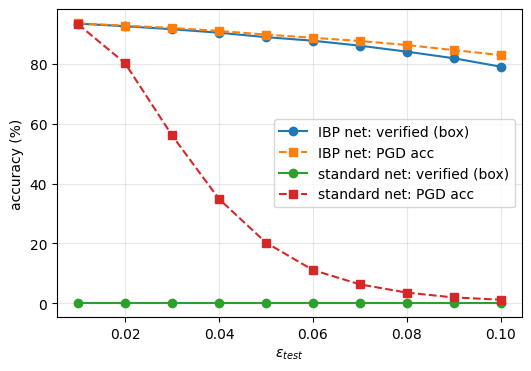

In [ ]:
eps_list = np.linspace(0.01, 0.1, 10)


def sweep(model, n=10000, batch_size=1000):
    model.eval()
    ver, att = [], []
    for eps in eps_list:
        v = p = 0
        for x, y in batches(x_test[:n], y_test[:n], batch_size, False):
            with torch.no_grad():
                correct = model(x).argmax(1) == y
            v += (box_verified(model, x, y, eps) & correct).sum().item()
            x_adv = pgd(model, x, y, eps, "linf", steps=50, restarts=3)
            with torch.no_grad():
                p += (correct & (model(x_adv).argmax(1) == y)).sum().item()
        ver.append(100 * v / n); att.append(100 * p / n)
        print(f"eps {eps:.2f}  verified {ver[-1]:6.2f}  PGD {att[-1]:6.2f}")
    return ver, att


print("IBP-trained network"); ibp_ver, ibp_pgd = sweep(ibp_model)
print("Standard network");     std_ver, std_pgd = sweep(std_model)

plt.figure(figsize=(6, 4))
plt.plot(eps_list, ibp_ver, "o-", label="IBP net: verified (box)")
plt.plot(eps_list, ibp_pgd, "s--", label="IBP net: PGD acc")
plt.plot(eps_list, std_ver, "o-", label="standard net: verified (box)")
plt.plot(eps_list, std_pgd, "s--", label="standard net: PGD acc")
plt.xlabel(r"$\epsilon_{test}$"); plt.ylabel("accuracy (%)"); plt.legend(); plt.grid(alpha=.3)
plt.show()

# (b) Adversarial examples where verification fails

For some $\epsilon_{test}$ the box verifier cannot certify all images. For the correctly classified images that are not certified,
we run PGD inside the ball and show examples where the attack changes the prediction.

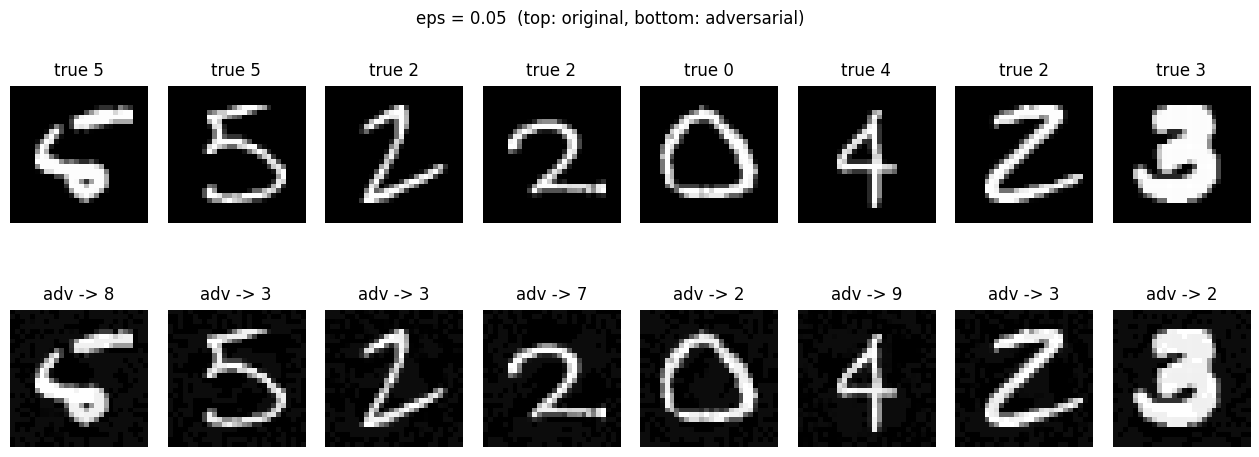

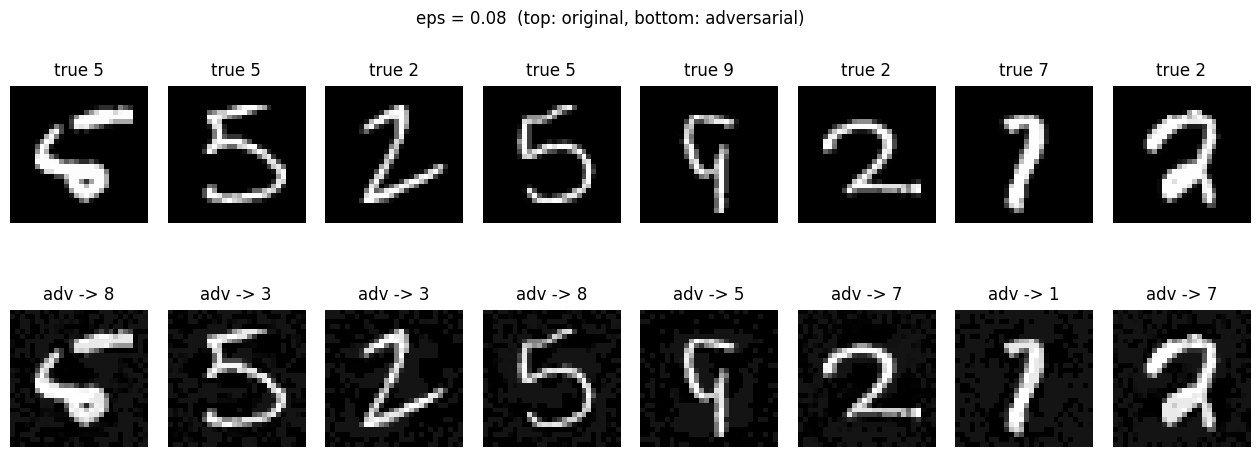

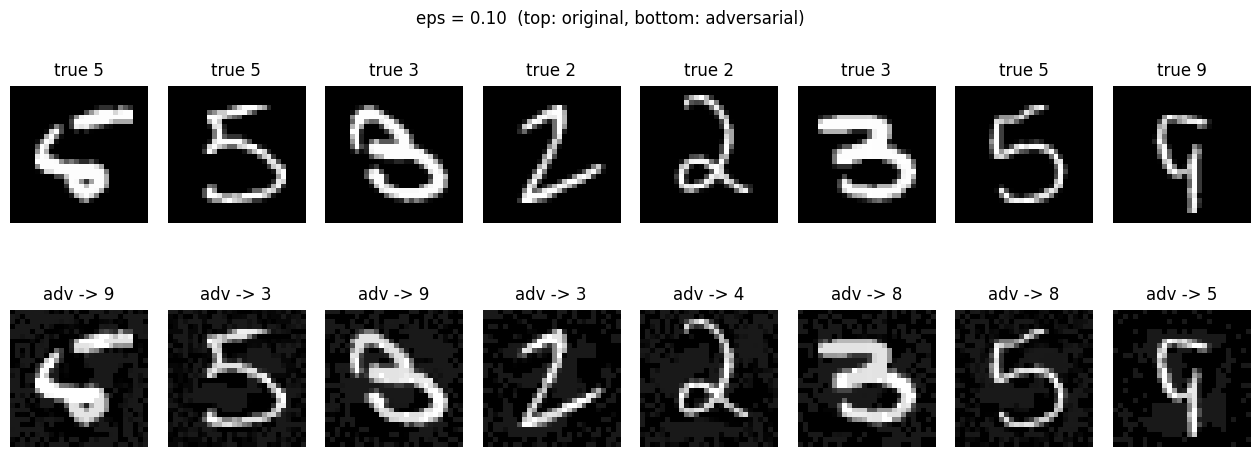

In [ ]:
def show_failures(model, eps, n_show=8, n_pool=2000):
    model.eval()
    x, y = x_test[:n_pool], y_test[:n_pool]
    with torch.no_grad():
        correct = model(x).argmax(1) == y
    unverified = correct & ~box_verified(model, x, y, eps)
    x_adv = pgd(model, x, y, eps, "linf", steps=100, restarts=5)
    with torch.no_grad():
        pred_adv = model(x_adv).argmax(1)
    idx = (unverified & (pred_adv != y)).nonzero().flatten()[:n_show]
    if len(idx) == 0:
        return
    fig, ax = plt.subplots(2, len(idx), figsize=(2.0 * len(idx), 5.2), squeeze=False)
    for j, i in enumerate(idx):
        ax[0, j].imshow(x[i, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax[0, j].set_title(f"true {y[i].item()}", pad=8)
        ax[1, j].imshow(x_adv[i, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax[1, j].set_title(f"adv -> {pred_adv[i].item()}", pad=8)
        for a in ax[:, j]: a.axis("off")
    fig.suptitle(f"eps = {eps:.2f}  (top: original, bottom: adversarial)", y=0.98)
    fig.subplots_adjust(hspace=0.35, top=0.86, wspace=0.15)
    plt.show()


for eps in [0.05, 0.08, 0.1]:
    show_failures(ibp_model, eps)

# Analysis

**(a)** Accuracies (in %) on the 10,000 test images with $\epsilon = 0.1$. The PGD accuracy is $\ell_\infty$ PGD with 50 steps and 3 restarts, as in the sweep of part (b)
(the `evaluate` cell above prints the PGD accuracy with 1 restart: 1.34 and 83.35). The verified accuracy is from the box verifier.

| Network | Standard accuracy | PGD accuracy | Verified accuracy | Time / epoch |
|---|---|---|---|---|
| Standard training | 97.50 | 1.21 | 0.00 | 0.4 s |
| IBP training | 94.31 | 82.94 | 79.06 | 0.8 s |

IBP training takes about 2x the time of standard training (0.8 s vs 0.4 s per epoch).

**(b)** The PGD accuracy (50 steps, 3 restarts) is an **upper bound** of the true robust accuracy.

* IBP network: the verified accuracy decreases monotonically from 93.46 ($\epsilon = 0.01$) to 79.06 ($\epsilon = 0.1$).
* The PGD accuracy of the IBP network is 0.09 to 3.88 higher than the verified accuracy, and the gap increases with $\epsilon_{test}$.
* Standard network: the box verifier certifies no image (0.00 for all $\epsilon_{test}$). The PGD accuracy decreases monotonically from 93.27 ($\epsilon = 0.01$) to 1.21 ($\epsilon = 0.1$).

**Adversarial examples.** For the IBP network, the figures show correctly classified images that the box verifier does not certify, and for which PGD (100 steps, 5 restarts) finds a misclassified image in the ball.

* The same images fail at several $\epsilon$: two digits 5 and one digit 2 appear in all three figures.
* The new, incorrect predictions are plausible confusions, digits that look similar to the true digit: 5 → 3, 8, 9; 2 → 3, 7; 3 → 8; 9 → 5.
* The perturbations are faint grey noise over the background and become more visible for larger $\epsilon$. The digits remain clearly recognisable.
